# Robot Data Quality & Success Prediction

真实机器人数据质量审计、固定前缀成功预测，以及独立的仿真清洗实验。

先按 README 在 D 盘完成依赖安装。默认 **inspect** 模式读取已生成的实测结果；改为 **reproduce** 会下载并重跑真实数据流程。没有输出时会明确报错，不生成虚构结果。完整实验、抽样检查与 CI 合成测试的证据层级分别记录。

In [1]:
import os, sys, subprocess, json
from pathlib import Path
ROOT=Path(os.environ.get('ROBOT_AUDIT_ROOT',Path.cwd())).resolve()
if not (ROOT/'configs/project.yaml').exists() and (ROOT.parent/'configs/project.yaml').exists(): ROOT=ROOT.parent
assert (ROOT/'configs/project.yaml').exists(), 'Run from the project folder'
sys.path.insert(0,str(ROOT/'src'))
from robot_audit.paths import Workspace
ws=Workspace(ROOT);ws.setup()
MODE='inspect'  # change to 'reproduce' for a full real-data rerun
assert MODE in ('inspect','reproduce')
def run(*arguments):
    subprocess.run([sys.executable,'-B','-m','robot_audit','--root',str(ROOT),*arguments],check=True,cwd=ROOT)
print('Workspace:',ROOT)


Workspace: D:\简历项目（重要）\robot-data-quality-success-prediction


## 1. 数据与审计
固定数据提交、标签冲突隔离、轨迹去重、结构与转换后时间戳检查。

In [2]:
if MODE=='reproduce':
    for command in ['fetch','audit','detect']: run(command)
audit=json.loads((ROOT/'reports/audit_summary.json').read_text(encoding='utf-8'))
assert audit['leakage_checks']=='PASS'
print(json.dumps(audit,indent=2,ensure_ascii=False))


{
  "audited_episodes": 15000,
  "predictor_eligible_episodes": 15000,
  "duplicate_content_or_prefix_episodes_excluded": 0,
  "structural_errors": 0,
  "rule_counts": {
    "frame_count_mismatch": 0,
    "nonmonotonic_timestamp": 0,
    "timestamp_nonfinite": 0,
    "frame_index_gap": 0
  },
  "timestamp_semantics": "15-Hz converted timestamps; original sensor-clock drift not measurable",
  "split_counts": {
    "train": 11674,
    "validation": 1679,
    "test": 1647
  },
  "split_classes": {
    "test": {
      "1": 1244,
      "0": 403
    },
    "train": {
      "1": 9444,
      "0": 2230
    },
    "validation": {
      "1": 1312,
      "0": 367
    }
  },
  "split_collectors": {
    "test": 10,
    "train": 53,
    "validation": 17
  },
  "feature_count": 156,
  "prefix_frames": 30,
  "video_coverage": "separate sample; never all episodes",
  "leakage_checks": "PASS"
}


## 2. 成功预测
只用前 30 帧运动特征；模型与阈值依验证集选择，测试集按采集者保留。

In [3]:
if MODE=='reproduce': run('train')
metrics=json.loads((ROOT/'reports/prediction_metrics.json').read_text(encoding='utf-8'))
import pandas as pd
display(pd.DataFrame({name:record['test'] for name,record in metrics['models'].items()}).T)
print('Validation-selected model:',metrics['selected_model'])


,roc_auc_success,pr_auc_success,pr_auc_failure,brier_score,failure_recall,failure_precision,failure_threshold,confusion_matrix_failure_positive
constant_prior,0.5,0.755313,0.244687,0.187695,1.0,0.244687,0.05,"[[0, 1244], [0, 403]]"
logistic_regression,0.647585,0.83151,0.376301,0.176847,0.533499,0.353618,0.22,"[[851, 393], [188, 215]]"
lightgbm,0.592218,0.801498,0.332957,0.183051,0.548387,0.307371,0.19,"[[746, 498], [182, 221]]"


Validation-selected model: lightgbm


## 3. 视频抽样与报告
视频只检查一个明确记录的样本。没有原始传感器时钟，不能据此判断原始时钟漂移。

# Research report: robot demonstration quality and success prediction

## Question and contribution
Can a reproducible audit identify review candidates in robot demonstrations, and can the first 30 frames predict eventual demonstration success under a collector-held-out split?

This project implements the data adapters, bounded/resumable downloads, motion features, quality rules, anomaly ranking, group-safe evaluation, and a separate controlled policy experiment. It does not introduce a new robot foundation model or claim real-robot deployment.

## Data and audit coverage
- Audited episodes: **15,000**; classifier-eligible episodes after content/prefix deduplication: **15,000**.
- Selected outcome counts: {'1': 12000, '0': 3000}; collectors in selection: 80.
- Upstream duplicate UUID rows: 36; conflicting UUIDs quarantined: 36.
- Review flags: 1,495. These are review suggestions, not verified corruptions.
- Timestamp checks apply to converted 15-Hz storage. Original sensor-clock drift is not measurable from these files.
- Video: {"sample_episodes": 30, "decoded_episodes": 30, "sample_cameras": ["observation.images.left_external"], "download_bytes": 6123971692, "video_quota_bytes": 8589934592, "frame_count_mismatches": 0, "decode_errors": 0, "sampling": "outcome x anomaly flag stratified sample, limited by shard byte budget", "scope": "Converted MP4 and converted timestamps only; not original sensor clocks; no whole-dataset video claim."}.

## Prediction protocol
Only fixed-prefix motion signals are allowed. Task text is absent for all failure episodes and is excluded, along with source path, IDs, full duration, outcome/reward and terminal data. Scaling, imputation, anomaly thresholds and model fitting use training data only. The failure threshold and presentation model are selected on validation data. Test collectors stay held out.

Actual split counts: {'train': 11674, 'validation': 1679, 'test': 1647}; collector counts: {'test': 10, 'train': 53, 'validation': 17}. Sampling deliberately targets an 80/20 outcome mix; precision and calibration reflect this sampled distribution, not an operational fleet prevalence.

| Model | Test ROC-AUC | Failure PR-AUC | Failure recall |
|---|---:|---:|---:|
| constant_prior | 0.500 | 0.245 | 1.000 |
| logistic_regression | 0.648 | 0.376 | 0.533 |
| lightgbm | 0.592 | 0.333 | 0.548 |

Validation-selected model: **lightgbm**. Test AUC 95% collector-bootstrap CI: [0.47261869261141887, 0.664463766944018]. Three baselines are prespecified; no search for a target AUC of 0.85 was performed. Full metrics, threshold and confusion matrices are in `prediction_metrics.json`.



## Feature interpretation and error inspection
| Prefix feature | Validation AUC drop after permutation | Repeat SD |
|---|---:|---:|
| `observation_joint_velocity_3_min` | 0.0108 | 0.0050 |
| `observation_joint_velocity_1_min` | 0.0096 | 0.0029 |
| `observation_cartesian_position_1_std` | 0.0065 | 0.0022 |
| `observation_joint_velocity_6_min` | 0.0065 | 0.0030 |
| `action_joint_velocity_1_mean_abs_delta` | 0.0060 | 0.0004 |

These are validation-set permutation results for the selected model, with three repeats. Feature indices are zero-based; `min`, `std` and `mean_abs_delta` summarize only the fixed 30-frame prefix. Small AUC drops describe model dependence on correlated motion signals, not causal effects or explanations for task failure.

| Case | Project episode ID | Predicted failure | Fixed alert threshold |
|---|---|---:|---:|
| False alert | `f24b95d3a390a7c43019` | 61.2% | 19.0% |
| Missed failure | `61f895a647e3bc8095e8` | 5.5% | 19.0% |

The false alert has the highest predicted failure probability among successful demonstrations; the missed failure has the lowest among failed demonstrations. These examples were chosen for inspection after the model and threshold were fixed. No task-failure cause is inferred from early motion alone, and the examples are not used for retraining or threshold selection.

## Controlled policy experiment
Status: **complete**.

- clean: 61.3% success (95% CI 50.0%–73.0%).
- contaminated: 22.7% success (95% CI 15.0%–31.7%).
- random_drop: 15.0% success (95% CI 8.0%–23.3%).
- audit_drop: 57.7% success (95% CI 48.3%–67.0%).
- oracle_drop: 62.3% success (95% CI 55.0%–69.7%).
Audit-filtered minus contaminated: 35.00 percentage points; CI [21.000000000000004, 48.66666666666667]. Simulation and injected corruptions only.

All 15 policies used 60,000 optimization steps and the same 100 initial-state seeds (10,000–10,099). The independent clean pilot used training seed 5 and separate starts (9,000–9,019), achieving 14/20 before the formal budget was frozen. Formal training seeds were 17, 29 and 43; the final fixed-step checkpoints were evaluated without test-based checkpoint selection.

The training masks contained 180 demonstrations; validation masks contained 20. Exactly 18 training demonstrations were corrupted (nine with action spikes and nine with action misalignment). Each filtering condition removed 18 demonstrations. Audit filtering recovered 10/18 injected cases, while random removal recovered 1/18. Random removal also reduced success below the contaminated baseline in this experiment, so sample removal alone did not provide the observed audit benefit. Audit filtering remained below the clean mean; the experiment does not establish complete recovery or unseen-task generalization.

Each of the 1,500 published CSV rows was checked against its original per-policy cloud record. An independent NumPy implementation recomputes all means and bootstrap intervals with `scripts/verify_policy_results.py`. Source, environment, protocol and injection hashes are retained in the adjacent JSON reports. No checkpoints or raw training data are redistributed.



## Limits and interpretation
- Labels describe human teleoperated demonstrations, not autonomous policy execution.
- The community conversion already removed some inconsistent episodes; findings do not estimate all raw DROID defects.
- Collector grouping tests transfer across collectors, not verified unseen scenes or unseen tasks.
- Success and failure cohorts come from separate converted repositories. Removing explicit source fields does not eliminate possible task, collection or conversion differences between cohorts; these may contribute to discrimination.
- Motion anomaly and task failure are separate concepts. Isolation Forest scores do not establish corruption or causation.
- A small, budget-limited video sample cannot establish whole-dataset camera quality.
- Controlled simulation results do not establish that filtering real DROID improves a physical robot.
- Policy uncertainty is limited by three training seeds, one Lift task and one fixed corruption draw. Bootstrap intervals do not establish generalization across tasks or corruption mixtures.

## Reproducibility
Pinned data commits: `source_versions.json`; downloaded file SHA256 values recorded. Project seed 42. Windows dependency versions: `requirements-lock-windows.txt`. Policy checkpoints include optimizer/RNG state. Formal policy comparisons require all 1,500 rollouts and identical initial-state hashes. CI uses synthetic fixtures clearly separated from real-data metrics.


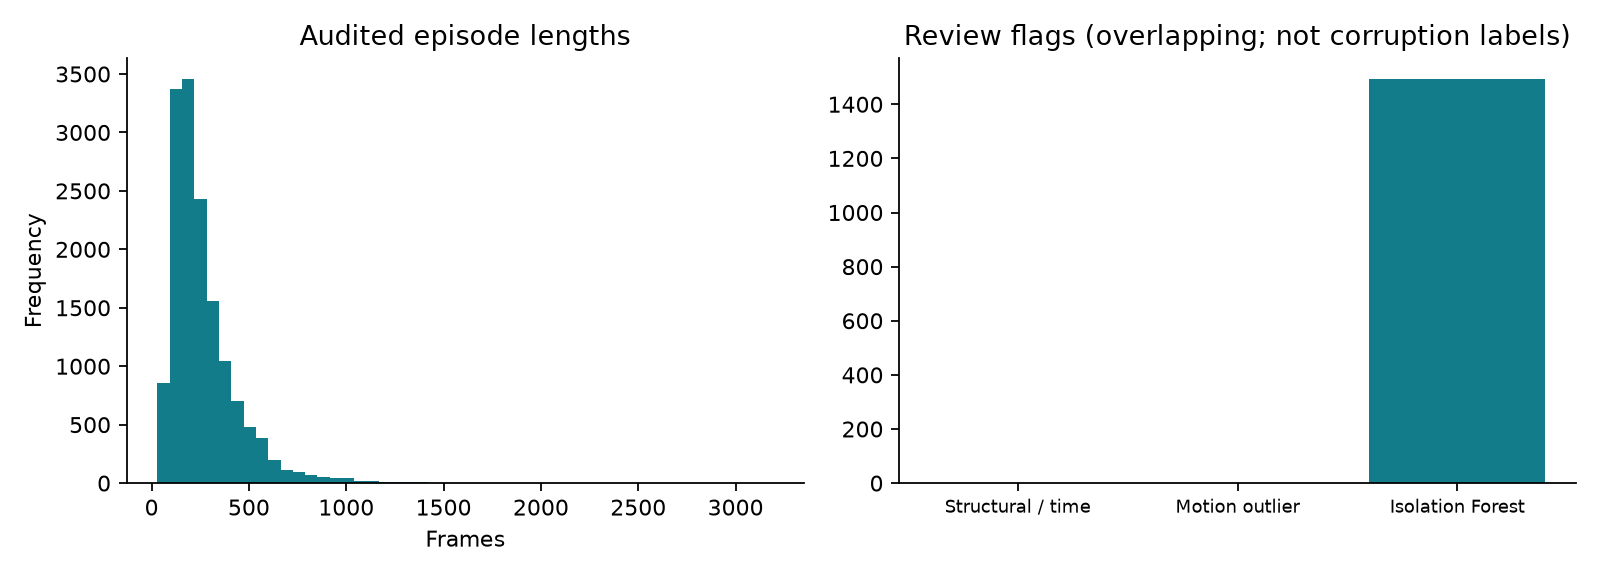

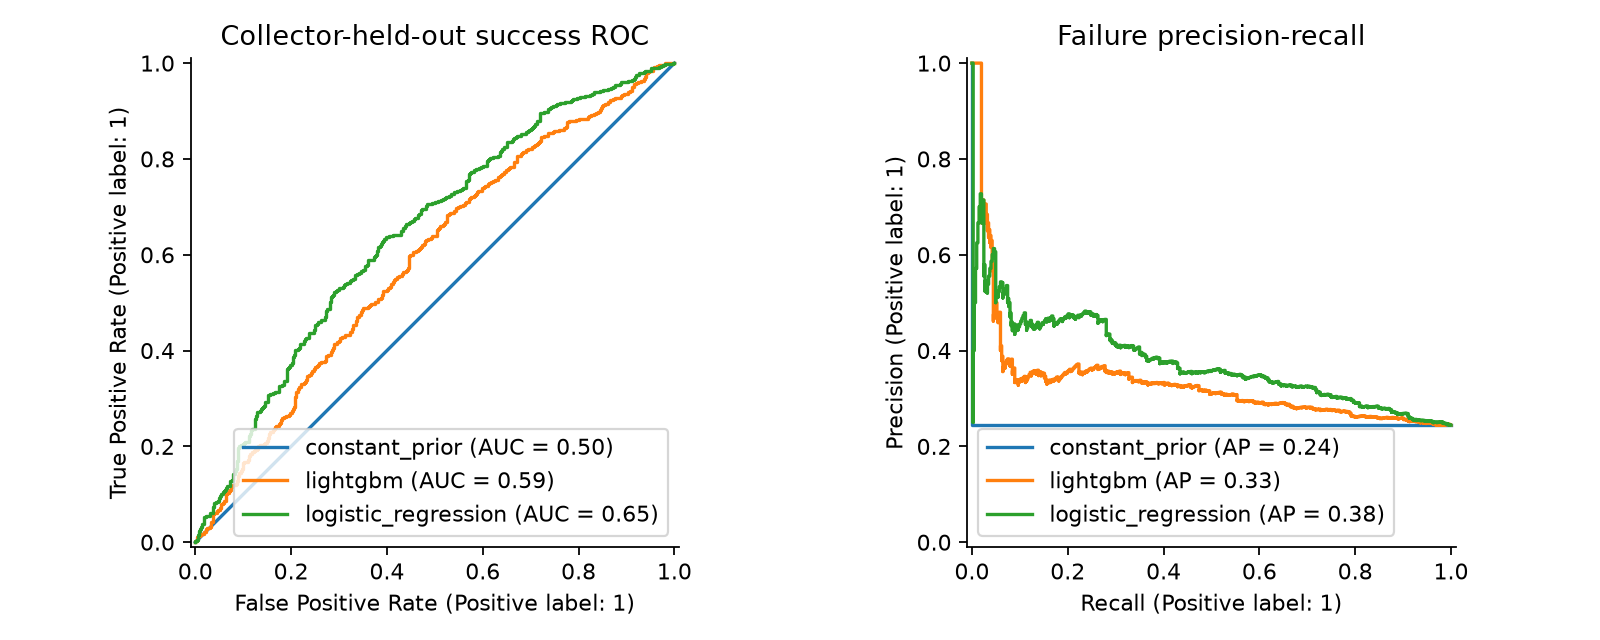

REAL-DATA REPORT INSPECTION PASS


In [4]:
if MODE=='reproduce':
    run('video','--episodes','30')
    run('report')
from IPython.display import Image, Markdown, display
import re
report=(ROOT/'reports/research_report.md').read_text(encoding='utf-8')
display(Markdown(re.sub(r'!\[[^\]]*\]\(figures/[^)]+\)','',report)))
for name in ['audit','prediction']:
    display(Image(filename=str(ROOT/f'reports/figures/{name}.png')))
print('REAL-DATA REPORT INSPECTION PASS' if MODE=='inspect' else 'REAL-DATA SEQUENTIAL RUN PASS')


## 4. 策略实验
用 `01_colab_policy.ipynb` 在 Colab 独立运行；达到五组 × 三种子 × 100 次评测并验证初始状态后，才生成 `policy_results.json`。免费配额不足时保留断点，不能将准备完成写成实验完成。

,success_rate,ci95
clean,0.613333,"[0.5, 0.73]"
contaminated,0.226667,"[0.15, 0.31666666666666665]"
random_drop,0.15,"[0.08, 0.23333333333333334]"
audit_drop,0.576667,"[0.48333333333333334, 0.67]"
oracle_drop,0.623333,"[0.55, 0.6966666666666667]"


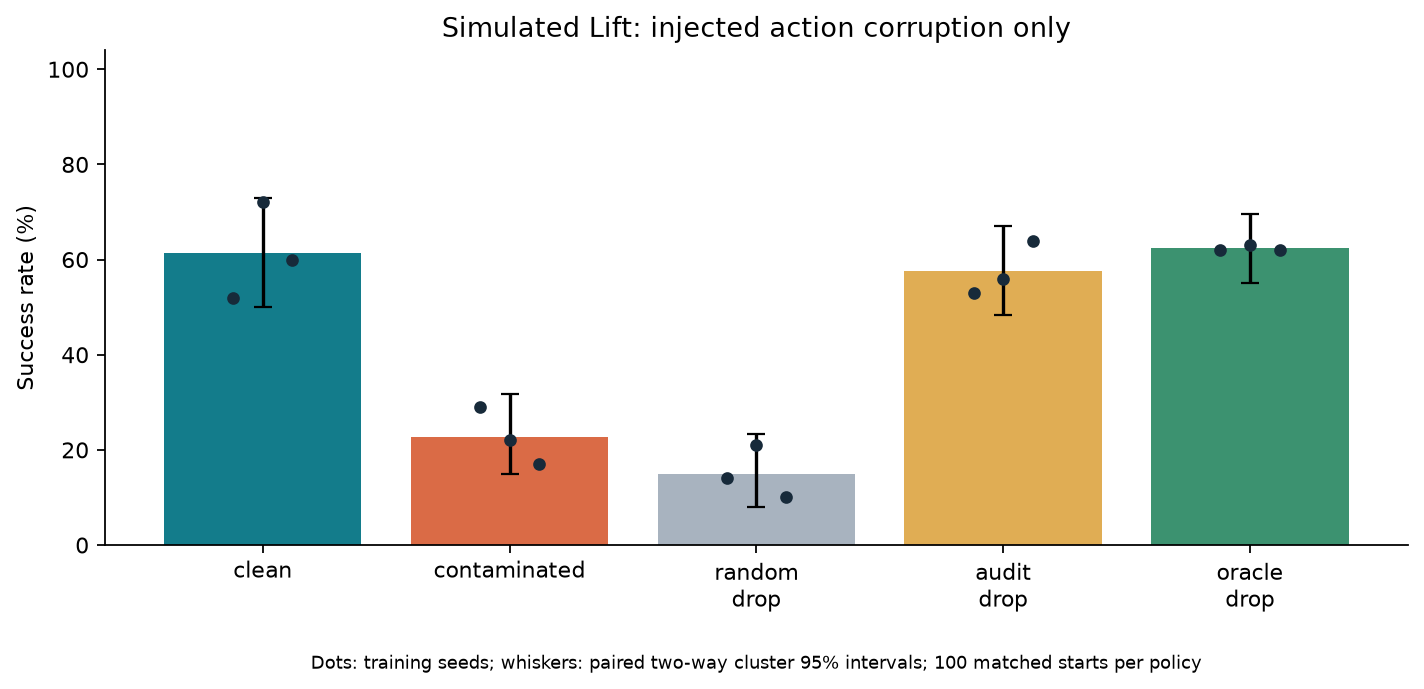

POLICY RESULT INSPECTION PASS


In [5]:
policy_path=ROOT/'reports/policy_results.json'
if policy_path.exists():
    policy=json.loads(policy_path.read_text(encoding='utf-8'))
    assert policy['status']=='complete' and policy['rollouts']==1500
    subprocess.run([sys.executable,'-B',str(ROOT/'scripts/verify_policy_results.py')],check=True,cwd=ROOT)
    display(pd.DataFrame(policy['conditions']).T)
    display(Image(filename=str(ROOT/'reports/figures/policy.png')))
    print('POLICY RESULT INSPECTION PASS')
else:
    print('POLICY EVALUATION PENDING: no improvement claim')
